In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold

import torch
from torch import nn

from kagglekit import (
    Dataset,
    LinearClassifier,
    MLP,
    Trainer,
    plot_histories,
    summarize_histories,
)

## Load Datasets

In [2]:
df = pd.read_csv('../data/train.csv')
df_test = pd.read_csv('../data/test.csv')

df.shape, df_test.shape

((891, 12), (418, 11))

## Preprocessing

In [3]:
# Spelling variants fold into their common title; everything else that is rare
# (one-off honorifics like Jonkheer, or test-only ones like Dona) becomes 'Rare'.
TITLE_ALIASES = {'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'}
COMMON_TITLES = ['Mr', 'Mrs', 'Miss', 'Master']

# Passengers per ticket, counted over train and test together (no labels involved).
# Fare is the price of the whole ticket, so it is split by this count.
TICKET_COUNTS = pd.concat([df, df_test])['Ticket'].value_counts()


def add_features(df):
    df = df.copy()

    title = df['Name'].str.extract(r',\s*([^.]*)\.')[0].str.strip().replace(TITLE_ALIASES)
    df['Title'] = title.where(title.isin(COMMON_TITLES), 'Rare')

    # Women in 1st/2nd class almost all survived, in 3rd only half; a linear model needs this spelled out.
    df['Sex_Pclass'] = df['Sex'] + '_' + df['Pclass'].astype(str)

    df['AgeMissing'] = df['Age'].isna().astype(int)
    df['HasCabin'] = df['Cabin'].notna().astype(int)

    df['TicketCount'] = df['Ticket'].map(TICKET_COUNTS)
    df['LogFarePP'] = np.log1p(df['Fare'] / df['TicketCount'])

    # Survival peaks for families of 2-4, so size is binned rather than kept linear.
    family_size = df['SibSp'] + df['Parch'] + 1
    df['FamilyGroup'] = pd.cut(family_size, bins=[0, 1, 4, np.inf], labels=['alone', 'small', 'large']).astype(str)

    return df.drop(
        columns=['PassengerId', 'Name', 'Ticket', 'Cabin', 'Survived', 'SibSp', 'Parch', 'Fare', 'Embarked'],
        errors='ignore',
    )


def woman_child_groups(df, X):
    """Family key for each woman or boy; NaN for men, who are left out of group survival."""
    is_woman_or_boy = (X['Sex'] == 'female') | (X['Title'] == 'Master')
    surname = df['Name'].str.split(',').str[0]

    # Relatives usually shared one ticket, so the fare separates unrelated people with the same surname.
    return (surname + '_' + df['Fare'].round(1).astype(str)).where(is_woman_or_boy)

In [4]:
class Preprocessor:
    def fit(self, df):
        X = add_features(df)

        # Survivors and known members per group, plus each fitted passenger's own label so
        # transform can leave it out.
        known = df['Survived'].groupby(woman_child_groups(df, X))
        self.group_survived = known.sum()
        self.group_known = known.count()
        self.own_label = df.set_index('PassengerId')['Survived']
        X = self._add_group_survival(df, X)

        # Title separates boys (Master) from men (Mr), so it fills Age far better than one global mean.
        self.age_by_title = X.groupby('Title')['Age'].median()
        self.fare_median = X['LogFarePP'].median()
        X = self._impute(X)

        self.numeric_cols = X.select_dtypes(include='number').columns.tolist()
        self.categorical_cols = X.select_dtypes(include=['object', 'string']).columns.tolist()

        self.means = X[self.numeric_cols].mean()
        self.stds = X[self.numeric_cols].std()

        self.columns = pd.get_dummies(X, columns=self.categorical_cols).columns
        
        return self

    def transform(self, df):
        X = self._impute(self._add_group_survival(df, add_features(df)))

        X[self.numeric_cols] = (X[self.numeric_cols] - self.means) / self.stds

        X = pd.get_dummies(X, columns=self.categorical_cols, dtype=int)
        
        return X.reindex(columns=self.columns, fill_value=0)

    def _add_group_survival(self, df, X):
        groups = woman_child_groups(df, X)

        # NaN for rows outside the fitted split (val/test), which have no label to remove.
        own = df['PassengerId'].map(self.own_label)
        survived = groups.map(self.group_survived) - own.fillna(0)
        known = groups.map(self.group_known) - own.notna()

        X['GroupDied'] = ((known > 0) & (survived == 0)).astype(int)
        X['GroupLived'] = ((known > 0) & (survived == known)).astype(int)

        return X

    def _impute(self, X):
        X['Age'] = X['Age'].fillna(X['Title'].map(self.age_by_title))

        return X.fillna({'LogFarePP': self.fare_median})

In [5]:
def to_tensor(data):
    return torch.tensor(data.to_numpy(), dtype=torch.float32)


def to_labels(df):
    return torch.tensor(df['Survived'].to_numpy(), dtype=torch.int64)

## Linear Classifier: Adam, lr=0.01, epochs=100

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_history = {}

for k, (train_idxs, val_idxs) in enumerate(skf.split(df, df['Survived'])):
    df_train = df.iloc[train_idxs]
    df_val = df.iloc[val_idxs]

    split_prep = Preprocessor().fit(df_train)

    df_train_X = split_prep.transform(df_train)
    df_val_X = split_prep.transform(df_val)

    X_train = to_tensor(df_train_X)
    X_val = to_tensor(df_val_X)

    Y_train = to_labels(df_train).float().reshape(-1, 1)
    Y_val = to_labels(df_val).float().reshape(-1, 1)

    torch.manual_seed(42)

    dataset = Dataset(X_train, Y_train, X_val, Y_val, batch_size=32)

    model = LinearClassifier(in_features=X_train.shape[1])
    
    loss_fn = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(model.parameters(), lr=0.01)
    
    trainer = Trainer(loss_fn, optim, max_epochs=100)
    
    history = trainer.fit(model, dataset)
    
    fold_history[k+1] = history

### CV Score

The epoch with the lowest mean val loss across folds, and each fold's score at that epoch.

In [7]:
val_loss = pd.DataFrame({k: h['val_loss'] for k, h in fold_history.items()})
val_accuracy = pd.DataFrame({k: h['val_accuracy'] for k, h in fold_history.items()})

# One epoch for all folds, chosen on the mean curve; per-fold bests would be optimistic.
best_epoch = int(val_loss.mean(axis=1).idxmin())

cv_scores = pd.DataFrame({
    'val_loss': val_loss.loc[best_epoch],
    'val_accuracy': val_accuracy.loc[best_epoch],
}).rename_axis('fold')

print(f'Best epoch: {best_epoch + 1}')

pd.concat([cv_scores, cv_scores.agg(['mean', 'std'])]).round(4)

Best epoch: 17


,val_loss,val_accuracy
1,0.3311,0.8603
2,0.3719,0.8315
3,0.4108,0.8427
4,0.3620,0.8371
5,0.3533,0.8539
mean,0.3658,0.8451
std,0.0293,0.0119


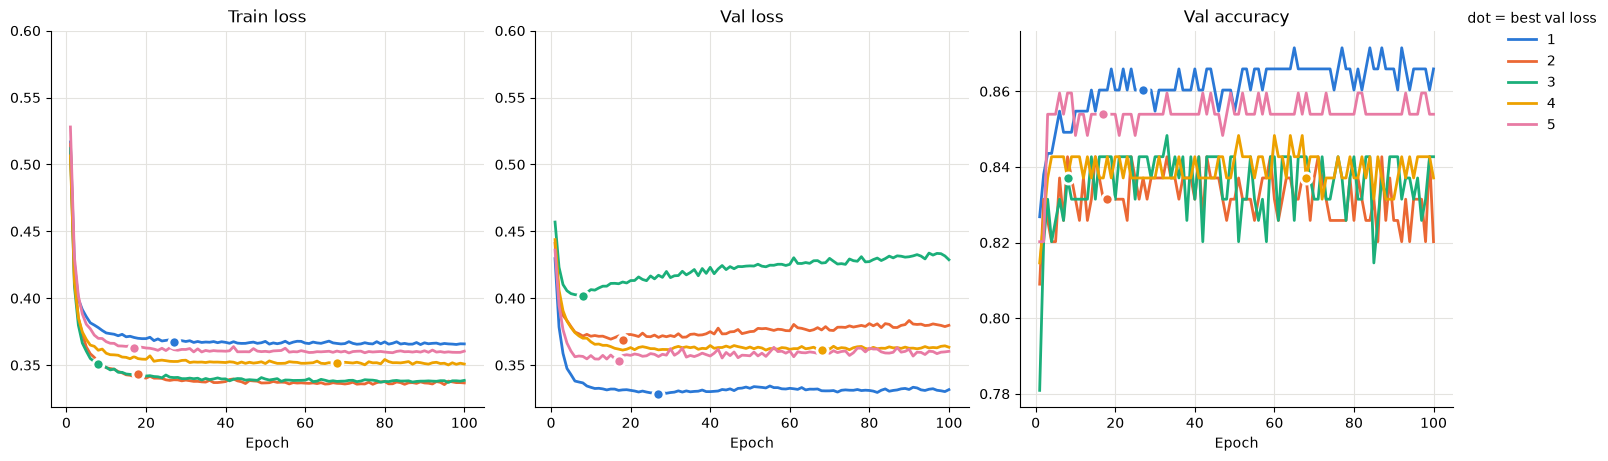

In [8]:
fig = plot_histories(fold_history)

## MLP: Adam, lr=0.001, epochs=100

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_history = {}

for k, (train_idxs, val_idxs) in enumerate(skf.split(df, df['Survived'])):
    df_train = df.iloc[train_idxs]
    df_val = df.iloc[val_idxs]

    split_prep = Preprocessor().fit(df_train)

    df_train_X = split_prep.transform(df_train)
    df_val_X = split_prep.transform(df_val)

    X_train = to_tensor(df_train_X)
    X_val = to_tensor(df_val_X)

    Y_train = to_labels(df_train).float().reshape(-1, 1)
    Y_val = to_labels(df_val).float().reshape(-1, 1)

    torch.manual_seed(42)

    dataset = Dataset(X_train, Y_train, X_val, Y_val, batch_size=32)

    model = MLP(in_features=X_train.shape[1], out_features=1)
    
    loss_fn = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(model.parameters(), lr=0.001)
    
    trainer = Trainer(loss_fn, optim, max_epochs=100)
    
    history = trainer.fit(model, dataset)
    
    fold_history[k+1] = history

### CV Score

In [10]:
val_loss = pd.DataFrame({k: h['val_loss'] for k, h in fold_history.items()})
val_accuracy = pd.DataFrame({k: h['val_accuracy'] for k, h in fold_history.items()})

# One epoch for all folds, chosen on the mean curve; per-fold bests would be optimistic.
best_epoch = int(val_loss.mean(axis=1).idxmin())

cv_scores = pd.DataFrame({
    'val_loss': val_loss.loc[best_epoch],
    'val_accuracy': val_accuracy.loc[best_epoch],
}).rename_axis('fold')

print(f'Best epoch: {best_epoch + 1}')

pd.concat([cv_scores, cv_scores.agg(['mean', 'std'])]).round(4)

Best epoch: 45


,val_loss,val_accuracy
1,0.3321,0.8436
2,0.3653,0.8483
3,0.4162,0.8202
4,0.3646,0.8483
5,0.3531,0.8539
mean,0.3663,0.8429
std,0.0310,0.0132


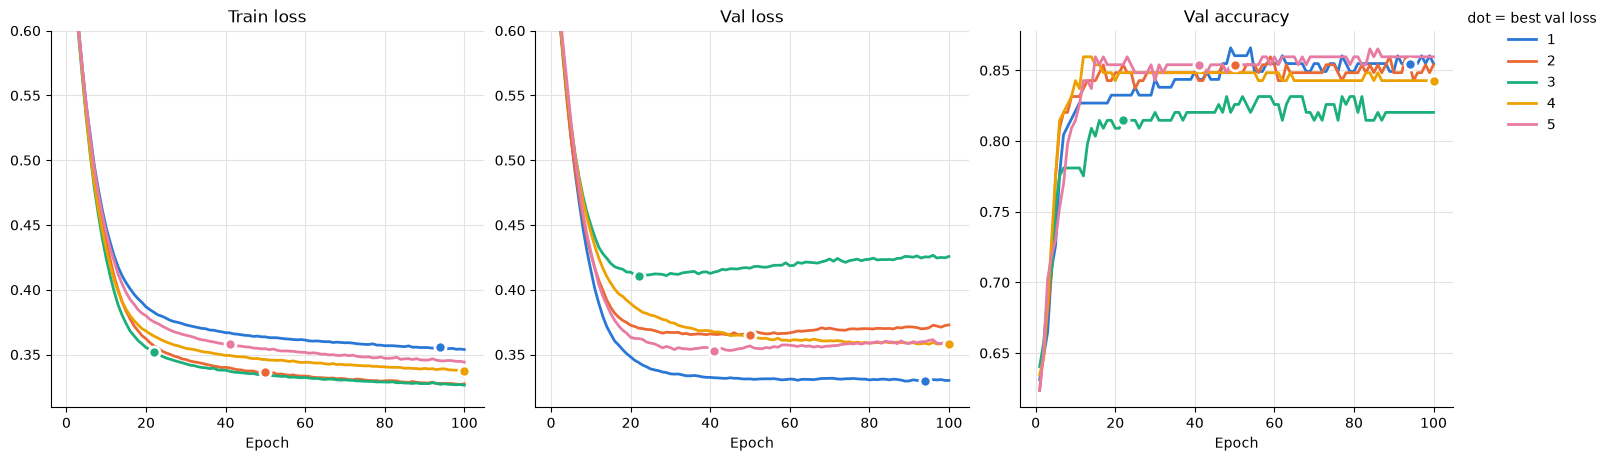

In [11]:
fig = plot_histories(fold_history)

## MLP: Adam, lr=0.01, epochs=100

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_history = {}

for k, (train_idxs, val_idxs) in enumerate(skf.split(df, df['Survived'])):
    df_train = df.iloc[train_idxs]
    df_val = df.iloc[val_idxs]

    split_prep = Preprocessor().fit(df_train)

    df_train_X = split_prep.transform(df_train)
    df_val_X = split_prep.transform(df_val)

    X_train = to_tensor(df_train_X)
    X_val = to_tensor(df_val_X)

    Y_train = to_labels(df_train).float().reshape(-1, 1)
    Y_val = to_labels(df_val).float().reshape(-1, 1)

    torch.manual_seed(42)

    dataset = Dataset(X_train, Y_train, X_val, Y_val, batch_size=32)

    model = MLP(in_features=X_train.shape[1], out_features=1)
    
    loss_fn = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(model.parameters(), lr=0.01)
    
    trainer = Trainer(loss_fn, optim, max_epochs=100)
    
    history = trainer.fit(model, dataset)
    
    fold_history[k+1] = history

In [13]:
val_loss = pd.DataFrame({k: h['val_loss'] for k, h in fold_history.items()})
val_accuracy = pd.DataFrame({k: h['val_accuracy'] for k, h in fold_history.items()})

# One epoch for all folds, chosen on the mean curve; per-fold bests would be optimistic.
best_epoch = int(val_loss.mean(axis=1).idxmin())

cv_scores = pd.DataFrame({
    'val_loss': val_loss.loc[best_epoch],
    'val_accuracy': val_accuracy.loc[best_epoch],
}).rename_axis('fold')

print(f'Best epoch: {best_epoch + 1}')

pd.concat([cv_scores, cv_scores.agg(['mean', 'std'])]).round(4)

Best epoch: 11


,val_loss,val_accuracy
1,0.3290,0.8436
2,0.3699,0.8483
3,0.4205,0.8258
4,0.3573,0.8371
5,0.3523,0.8596
mean,0.3658,0.8429
std,0.0340,0.0126


## 4-Layer MLP:  Adam, lr=0.001, epochs=100

In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_history = {}

for k, (train_idxs, val_idxs) in enumerate(skf.split(df, df['Survived'])):
    df_train = df.iloc[train_idxs]
    df_val = df.iloc[val_idxs]

    split_prep = Preprocessor().fit(df_train)

    df_train_X = split_prep.transform(df_train)
    df_val_X = split_prep.transform(df_val)

    X_train = to_tensor(df_train_X)
    X_val = to_tensor(df_val_X)

    Y_train = to_labels(df_train).float().reshape(-1, 1)
    Y_val = to_labels(df_val).float().reshape(-1, 1)

    torch.manual_seed(42)

    dataset = Dataset(X_train, Y_train, X_val, Y_val, batch_size=32)

    model = MLP(in_features=X_train.shape[1], out_features=1, hidden_features=[32, 16, 8])
    
    loss_fn = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(model.parameters(), lr=0.001)
    
    trainer = Trainer(loss_fn, optim, max_epochs=100)
    
    history = trainer.fit(model, dataset)
    
    fold_history[k+1] = history

In [15]:
val_loss = pd.DataFrame({k: h['val_loss'] for k, h in fold_history.items()})
val_accuracy = pd.DataFrame({k: h['val_accuracy'] for k, h in fold_history.items()})

# One epoch for all folds, chosen on the mean curve; per-fold bests would be optimistic.
best_epoch = int(val_loss.mean(axis=1).idxmin())

cv_scores = pd.DataFrame({
    'val_loss': val_loss.loc[best_epoch],
    'val_accuracy': val_accuracy.loc[best_epoch],
}).rename_axis('fold')

print(f'Best epoch: {best_epoch + 1}')

pd.concat([cv_scores, cv_scores.agg(['mean', 'std'])]).round(4)

Best epoch: 12


,val_loss,val_accuracy
1,0.3315,0.8547
2,0.3649,0.8708
3,0.4270,0.8371
4,0.3634,0.8539
5,0.3510,0.8596
mean,0.3676,0.8552
std,0.0358,0.0122


## 5-Layer MLP: Adam, lr=0.001, epochs=100

In [18]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_history = {}

for k, (train_idxs, val_idxs) in enumerate(skf.split(df, df['Survived'])):
    df_train = df.iloc[train_idxs]
    df_val = df.iloc[val_idxs]

    split_prep = Preprocessor().fit(df_train)

    df_train_X = split_prep.transform(df_train)
    df_val_X = split_prep.transform(df_val)

    X_train = to_tensor(df_train_X)
    X_val = to_tensor(df_val_X)

    Y_train = to_labels(df_train).float().reshape(-1, 1)
    Y_val = to_labels(df_val).float().reshape(-1, 1)

    torch.manual_seed(42)

    dataset = Dataset(X_train, Y_train, X_val, Y_val, batch_size=32)

    model = MLP(in_features=X_train.shape[1], out_features=1, hidden_features=[64, 32, 16, 8])
    
    loss_fn = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(model.parameters(), lr=0.01)
    
    trainer = Trainer(loss_fn, optim, max_epochs=100)
    
    history = trainer.fit(model, dataset)
    
    fold_history[k+1] = history

In [19]:
val_loss = pd.DataFrame({k: h['val_loss'] for k, h in fold_history.items()})
val_accuracy = pd.DataFrame({k: h['val_accuracy'] for k, h in fold_history.items()})

# One epoch for all folds, chosen on the mean curve; per-fold bests would be optimistic.
best_epoch = int(val_loss.mean(axis=1).idxmin())

cv_scores = pd.DataFrame({
    'val_loss': val_loss.loc[best_epoch],
    'val_accuracy': val_accuracy.loc[best_epoch],
}).rename_axis('fold')

print(f'Best epoch: {best_epoch + 1}')

pd.concat([cv_scores, cv_scores.agg(['mean', 'std'])]).round(4)

Best epoch: 3


,val_loss,val_accuracy
1,0.3322,0.8715
2,0.3767,0.8315
3,0.4355,0.8146
4,0.3628,0.8427
5,0.3771,0.8371
mean,0.3769,0.8395
std,0.0375,0.0208
